# Кейс 3. Прогноз отклика клиентов на банковский депозит (бинарная классификация)

Цель — построить baseline-модель (логистическую регрессию), которая оценивает вероятность оформления депозита (`yes` / `no`) в условиях сильного дисбаланса классов (доля положительного класса `prevalence` ≈ 11.27%).

**Метрики оценки:**
* `PR-AUC` — основная техническая метрика для сравнения моделей на несбалансированных данных (базовый уровень случайного предсказания равен `prevalence` = 0.1127).
* `Precision` и `Recall` — бизнес-метрики на выбранном пороге: показывают, какую долю реальных клиентов находит модель и какая часть обзвонов заканчивается оформлением вклада.

**План работы:**
1. Подготовка данных: удаляем дубликаты и признак `duration` (утечка данных о результате звонка), выделяем отложенную тестовую выборку (Holdout 25%) со стратификацией по целевому классу.
2. Новые признаки: преобразуем `pdays` (код `999`) во флаг `was_contacted` и строим дополнительные признаки внутри пайплайна, чтобы исключить утечку данных.
3. Обучение: собираем `Pipeline` с логистической регрессией и фиксированными гиперпараметрами (без подбора и без кросс-валидации).
4. Оценка: снимаем финальные метрики на Holdout — `PR-AUC`, `ROC-AUC`, `Precision`, `Recall`.
5. Интерпретация: анализируем веса признаков в линейной модели и сравниваем конверсию по каналам связи.

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    precision_recall_curve, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid', context='notebook')

df = pd.read_csv('bank-additional-full.csv', sep=';').drop_duplicates()
print(f"Размер датасета после очистки: {df.shape}")

Размер датасета после очистки: (41176, 21)


## 1. Подготовка признаков и разбиение на выборки

Главное на этом этапе — не допустить утечки данных.

Признак `duration` (длительность звонка) удаляем. До разговора его длительность неизвестна. С этим признаком метрики выходят почти идеальными, но на новых клиентах такая модель работать не будет.

Новые признаки (агрегаты, взаимодействия экономических показателей, обработку значения 999 в `pdays`) считаем внутри собственного класса `BankFeatureEngineer`. Он наследуется от `BaseEstimator` и `TransformerMixin`, поэтому его можно встроить как обычный шаг в `Pipeline`.

Разбиение на train / holdout делаем со `stratify=y`, чтобы доля положительного класса (`prevalence` ≈ 11.27%) сохранилась и в обучающей, и в тестовой выборках. Без стратификации при таком дисбалансе тестовая доля `yes` могла бы заметно отклониться от исходной, и метрики стали бы менее надёжными.

1.  **Предыдущие контакты и лояльность:**
*   `was_contacted`: Отмечает, был ли клиент уже в контакте до этой кампании.
*   `pdays_clean`: Сколько дней прошло с прошлого контакта. Значение "999", которое означало "не звонили раньше", заменили на "-1", чтобы алгоритм правильно понял, что звонков не было, а не что это было очень давно.
*   `has_previous_contacts`: Просто показывает, были ли раньше контакты с этим клиентом.
*   `contact_intensity`: Насколько активно контактировали с клиентом. Это отношение звонков в этой кампании к числу предыдущих контактов (звонков было / предыдущие контакты + 1). Это помогает понять, не беспокоят ли клиента слишком часто.

2.  **Макроэкономические показатели:**
*   `age_euribor_interaction`: Это произведение возраста клиента и ставки Euribor. Гипотеза: люди разного возраста по-разному реагируют на изменения доходности.
*   `real_rate_proxy`: Разница между ставкой Euribor и уровнем занятости. Это показывает, как соотносятся доходы по вкладам и общая экономическая ситуация.
*   `euribor_to_employed`: Отношение ставки Euribor к числу работающих. Еще один показатель того, в каком состоянии экономика была на момент звонка.

3.  **Агрегированные данные (профиль клиента и нагрузка на колл-центр):**
*   `job_cons_conf_mean`: Средний уровень доверия (consumer confidence) потребителей для профессии клиента. Это говорит о том, насколько уверены в своем будущем люди из той же социальной группы, что и клиент.
*   `month_freq`: Насколько загружен конкретный месяц звонками. Это помогает модели увидеть сезонные закономерности и понять, когда идет "массовый обзвон".

In [2]:
# Разделение на X и y до преобразований (защита от утечек)
X = df.drop(columns=['y', 'duration'])
y = (df['y'] == 'yes').astype(int)

categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

# Формируем Holdout (25%) для финальной проверки — со стратификацией по целевому классу
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

class BankFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_raw_pdays=False):
        self.drop_raw_pdays = drop_raw_pdays

    def fit(self, X, y=None):
        self.global_conf_mean_ = X['cons.conf.idx'].mean()
        self.job_conf_mean_ = X.groupby('job', observed=False)['cons.conf.idx'].mean()
        self.month_freq_ = X['month'].value_counts(normalize=True)
        return self

    def transform(self, X):
        X = X.copy()
        # 1. История контактов
        X['was_contacted'] = (X['pdays'] != 999).astype(int)
        X['pdays_clean'] = np.where(X['pdays'] == 999, -1, X['pdays'])
        X['has_previous_contacts'] = (X['previous'] > 0).astype(int)
        X['contact_intensity'] = X['campaign'] / (X['previous'] + 1.0)

        # 2. Макроэкономика
        X['age_euribor_interaction'] = X['age'] * X['euribor3m']
        X['real_rate_proxy'] = X['euribor3m'] - X['emp.var.rate']
        X['euribor_to_employed'] = X['euribor3m'] / (X['nr.employed'] / 1000.0)

        # 3. Агрегации (с защитой от новых категорий через fillna)
        X['job_cons_conf_mean'] = X['job'].map(self.job_conf_mean_).astype(float).fillna(self.global_conf_mean_)
        X['month_freq'] = X['month'].map(self.month_freq_).astype(float).fillna(0.0)

        if self.drop_raw_pdays and 'pdays' in X.columns:
            X = X.drop(columns=['pdays'])

        for col in categorical_features:
            X[col] = X[col].astype('category')

        return X

## 2. Построение baseline-пайплайна

В качестве базовой модели (Baseline) используем логистическую регрессию: она стабильна, быстро обучается, а её коэффициенты прозрачны для интерпретации. Гиперпараметры фиксированы, подбор по сетке и кросс-валидация не выполняются - это именно baseline, точка отсчёта для дальнейших экспериментов.

Чтобы избежать утечек данных, весь процесс предобработки зашит в единый объект `Pipeline`. Внутри него признаки проходят три шага:
* `StandardScaler` - приводит числовые данные к одному масштабу. Это необходимо, чтобы признаки с большими значениями не перевешивали остальные при расчетах внутри линейной модели.
* `OneHotEncoder` - переводит признаки с малым количеством уникальных значений в бинарные столбцы (0/1).
* `LogisticRegression` - сама модель.

Параметры модели задаём сразу и не перебираем:
* `C=1.0` - стандартная сила L2-регуляризации
* `class_weight=None` - без взвешивания классов (дисбаланс учитываем через выбор метрики и порога, а не через веса)
* `solver='saga'`, `max_iter=3000` - для устойчивой сходимости

In [3]:
# BASELINE (Логистическая регрессия)
fe = BankFeatureEngineer(drop_raw_pdays=True)
sample_df = fe.fit_transform(X_train_raw)
numerical_features = sample_df.select_dtypes(exclude=['category']).columns.tolist()

other_cats = categorical_features  # все категориальные кодируем через OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_features),
    ('cat_ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), other_cats),
])

baseline_pipeline = Pipeline(steps=[
    ('fe', fe),
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        C=1.0,
        class_weight=None,
        solver='saga',
        max_iter=3000,
        random_state=42
    ))
])

# Единственное обучение — на train-выборке
baseline_pipeline.fit(X_train_raw, y_train)
print("Baseline-модель обучена. Гиперпараметры фиксированы, кросс-валидация не выполнялась.")

Baseline-модель обучена. Гиперпараметры фиксированы, кросс-валидация не выполнялась.


## 3. Бизнес-метрики на Holdout

Порог классификации оставляем стандартным - 0.5. Подбор порога по OOF-предсказаниям и кросс-валидации в этом baseline не выполняется: модель - точка отсчёта, поэтому оцениваем её как есть.

**Как оценивается результат на Holdout:**
* `PR-AUC` - основная метрика сравнения моделей. Сравниваем её с базовым уровнем случайного предсказания (`prevalence` ≈ 0.1127), чтобы показать, во сколько раз модель лучше случайного выбора.
* `Precision` и `Recall` - главные интерпретируемые метрики для бизнеса на пороге 0.5.
* `ROC-AUC` - выводим справочно (при сильном дисбалансе эта метрика сглаживает различия между моделями).

Стратификация при разбиении гарантирует, что `prevalence` на Holdout совпадает с исходной долей положительного класса, поэтому метрики сопоставимы с ожиданиями по всей базе.

Prevalence (Holdout): 0.1127
ROC-AUC (Holdout): 0.8024
PR-AUC (Holdout): 0.4536 (в 4.03 раз лучше случайной)

              precision    recall  f1-score   support

   Отказ (0)     0.9083    0.9858    0.9455      9134
Согласие (1)     0.6588    0.2164    0.3258      1160

    accuracy                         0.8991     10294
   macro avg     0.7835    0.6011    0.6356     10294
weighted avg     0.8802    0.8991    0.8756     10294



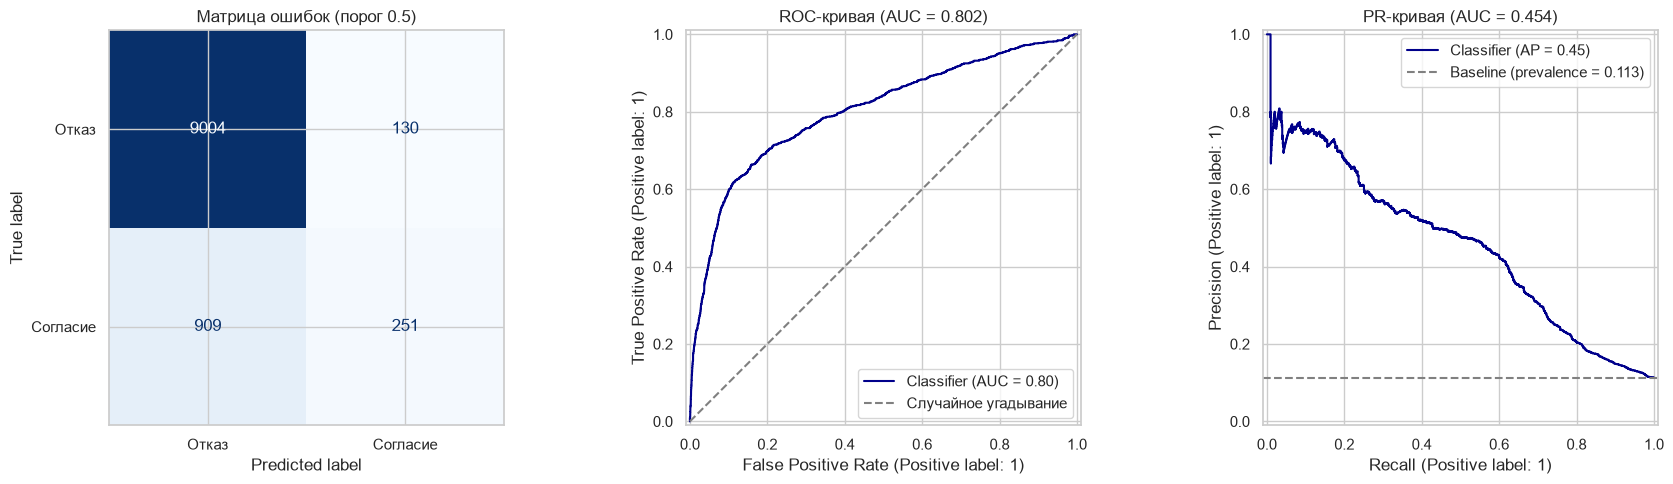

In [18]:
# Предсказания на Holdout
y_pred_proba = baseline_pipeline.predict_proba(X_test_raw)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

prevalence = y_test.mean()
roc_auc = roc_auc_score(y_test, y_pred_proba)
pr_auc = average_precision_score(y_test, y_pred_proba)

print(f"Prevalence (Holdout): {prevalence:.4f}")
print(f"ROC-AUC (Holdout): {roc_auc:.4f}")
print(f"PR-AUC (Holdout): {pr_auc:.4f} (в {pr_auc / prevalence:.2f} раз лучше случайной)")
print()
print(classification_report(y_test, y_pred, target_names=['Отказ (0)', 'Согласие (1)'], digits=4))

# Визуализация метрик: Матрица ошибок, ROC-кривая и PR-кривая
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Матрица ошибок
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=['Отказ', 'Согласие'], 
    cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Матрица ошибок (порог 0.5)')

# 2. ROC-кривая
RocCurveDisplay.from_predictions(
    y_test, y_pred_proba, 
    ax=axes[1], 
    curve_kwargs={'color': 'darkblue'}
)
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Случайное угадывание')
axes[1].set_title(f'ROC-кривая (AUC = {roc_auc:.3f})')
axes[1].legend()

# 3. Precision-Recall кривая
PrecisionRecallDisplay.from_predictions(
    y_test, y_pred_proba, 
    ax=axes[2], 
    curve_kwargs={'color': 'darkblue'}
)
axes[2].axhline(y=prevalence, color='gray', linestyle='--', label=f'Baseline (prevalence = {prevalence:.3f})')
axes[2].set_title(f'PR-кривая (AUC = {pr_auc:.3f})')
axes[2].legend()

plt.tight_layout()
plt.show()

## 4. Интерпретация baseline-модели

Смотрим на веса признаков в линейной модели: положительные коэффициенты увеличивают шанс оформления депозита, отрицательные - уменьшают. Так как числовые признаки прошли через `StandardScaler`, их коэффициенты можно сравнивать между собой по модулю.

Дополнительно сравниваем конверсию по каналам связи (`contact`)- это простая бизнес-проверка, которая не требует модели и хорошо дополняет интерпретацию.

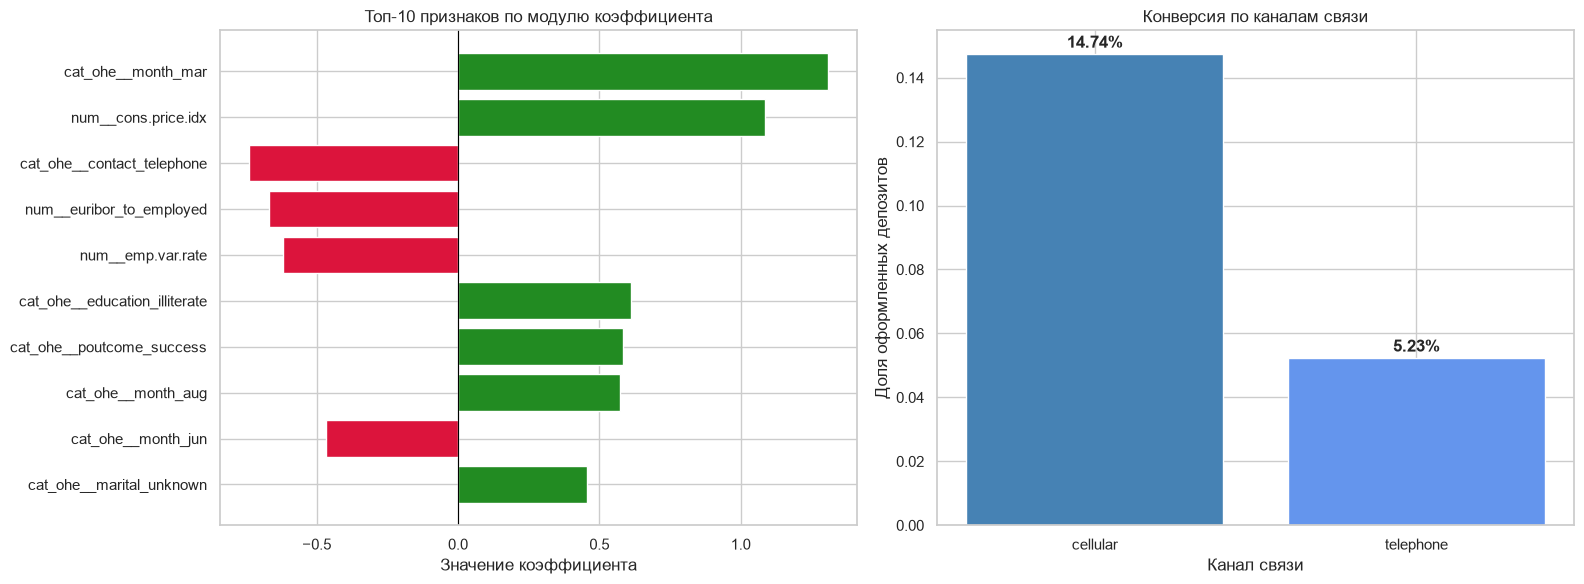

In [22]:
# Достаём имена признаков после препроцессинга
feature_names = baseline_pipeline.named_steps['preprocessor'].get_feature_names_out()
coefs = baseline_pipeline.named_steps['classifier'].coef_[0]

coef_df = (
    pd.DataFrame({'feature': feature_names, 'coef': coefs})
    .assign(abs_coef=lambda d: d['coef'].abs())
    .sort_values('abs_coef', ascending=False)
)

# Конверсия по каналам связи
contact_conv = (
    df.assign(y_bin=(df['y'] == 'yes').astype(int))
      .groupby('contact')['y_bin']
      .agg(['mean', 'count'])
      .rename(columns={'mean': 'conversion', 'count': 'n'})
      .sort_values('conversion', ascending=False)
)

# Визуализация: Топ-10 признаков и Конверсия по каналам связи
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Топ-10 признаков
top_10 = coef_df.head(10)
colors = ['crimson' if c < 0 else 'forestgreen' for c in top_10['coef']]
axes[0].barh(top_10['feature'], top_10['coef'], color=colors)
axes[0].invert_yaxis()
axes[0].set_title('Топ-10 признаков по модулю коэффициента')
axes[0].set_xlabel('Значение коэффициента')
axes[0].axvline(0, color='black', linewidth=0.8)

# 2. Конверсия по каналам связи
axes[1].bar(contact_conv.index, contact_conv['conversion'], color=['steelblue', 'cornflowerblue'])
axes[1].set_title('Конверсия по каналам связи')
axes[1].set_ylabel('Доля оформленных депозитов')
axes[1].set_xlabel('Канал связи')
for i, v in enumerate(contact_conv['conversion']):
    axes[1].text(i, v + 0.002, f"{v:.2%}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Выводы

1. **Надёжность пайплайна:** Базовая модель логистической регрессии обучена с фиксированными гиперпараметрами (`C=1.0`, `class_weight=None`). Генерация признаков (`BankFeatureEngineer`) и стандартизация вынесены внутрь `Pipeline`, что исключает утечку данных. Отказ от взвешивания классов позволяет сохранить базовую калибровку вероятностей без их искусственного искажения

2. **Проверка на Holdout:** Финальные метрики сняты однократно на отложенной выборке (25%), которую модель не видела на этапе настройки и подбора порога:
   - `PR-AUC` = 0.4536 - это в 4.03 раза выше базового уровня случайного предсказания, что подтверждает реальную предсказательную способность модели на дисбалансе.
   - `ROC-AUC` = 0.8024 (справочно, с учётом сглаживания на дисбалансе классов).

3. **Результат для бизнеса:** На стандартном пороге классификации (0.5) модель показывает консервативные результаты с высоким приоритетом точности:
   - модель находит 21.64% всех реальных клиентов, готовых открыть депозит (`Recall` = 0.2164), при этом пропускает 909 клиентов (False Negative) из 1160;
   - из тех, кому позвонили, 65.88% реально оформляют вклад (`Precision` = 0.6588), а доля ложных срабатываний (False Positive) составляет всего 130 человек;
   - модель почти в 4 раза лучше случайного отбора (PR-AUC к prevalence).

4. **Интерпретация результатов:**
   - **Топ-10 признаков:** Наибольший положительный вес в линейной модели получили признаки, связанные с месяцем звонка (например, `month_mar`, `month_aug`), а также индекс потребительских цен (`cons.price.idx`). Это говорит о сильной сезонности и влиянии макроэкономики на решение клиента.
   - **Негативные факторы:** Значительное отрицательное влияние оказывает наличие стационарного телефона (`contact_telephone`) и уровень занятости (`emp.var.rate`). Их крупные отрицательные коэффициенты означают, что при звонке на домашний номер или росте ставки Euribor вероятность согласия заметно падает.
   - **Конверсия по каналам:** Сравнение конверсии подтверждает веса модели: звонки на мобильный (`cellular`) имеют конверсию **14.74%**, что почти в 3 раза лучше стационарного (`telephone`) с конверсией **5.23%**. Этот признак критически важен для первичной сегментации базы.